# A 5-gram language model

A 5-gram is four context tokens plus one next token. If we've never seen those four together, try the last three, then two, then one. Dropping the oldest token is called **backoff**.

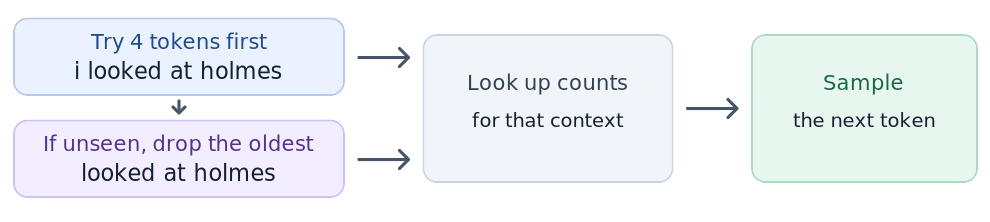

## Data

Two Sherlock Holmes collections for training ([Adventures](https://www.gutenberg.org/ebooks/1661), [Memoirs](https://www.gutenberg.org/ebooks/834)); a separate collection for testing ([Return](https://www.gutenberg.org/ebooks/108)). Each file has one roughly segmented sentence per line. We lowercase the text and treat common punctuation as separate tokens.

In [11]:
from collections import Counter, defaultdict
from pathlib import Path
import random
import re

train_rows = Path("data/holmes_train.txt").read_text(encoding="utf-8").splitlines()
test_rows = Path("data/holmes_test.txt").read_text(encoding="utf-8").splitlines()
print(f"{len(train_rows):,} train rows | {len(test_rows):,} test rows")
print(train_rows[5])


def tokenize(text):
    text = text.lower().replace("’", "'")
    return re.findall(r"[a-z]+(?:'[a-z]+)*|\d+|[.,!?;:]", text)

12,420 train rows | 7,645 test rows
He was, I take it, the most perfect reasoning and observing machine that the world has seen, but as a lover he would have placed himself in a false position.


## Train

Slide a window through each row. For each target, count it after all five context lengths (4, 3, 2, 1, 0). The empty tuple holds the overall token counts and is the last resort.

In [12]:
N = 5
start = ("<start>",) * (N - 1)
model = defaultdict(Counter)

for row in train_rows:
    context = start
    for token in tokenize(row) + ["<end>"]:
        for i in range(N):
            model[context[i:]][token] += 1
        context = (context + (token,))[1:]

print(f"{len(model):,} distinct contexts across all lengths")


def next_counts(context):
    while context not in model:
        context = context[1:]
    return model[context]

433,408 distinct contexts across all lengths


## Test on unseen stories

Give each model the **actual** previous tokens, then check whether its top guess is correct. The trigram uses the same training counts but can start with only two previous tokens. Four-token coverage ignores the start padding. Accuracy includes punctuation and `<end>`.

In [13]:
total = correct_3 = correct_5 = 0
four_token_positions = full_matches = 0

for row in test_rows:
    context = start
    for token in tokenize(row) + ["<end>"]:
        correct_3 += next_counts(context[-2:]).most_common(1)[0][0] == token
        correct_5 += next_counts(context).most_common(1)[0][0] == token
        total += 1
        if "<start>" not in context:
            four_token_positions += 1
            full_matches += context in model
        context = (context + (token,))[1:]

print(f"Test tokens: {total:,}")
print(f"Trigram top-1 accuracy: {correct_3 / total:.1%}")
print(f"5-gram top-1 accuracy:  {correct_5 / total:.1%}")
print(f"Four-token coverage:   {full_matches / four_token_positions:.1%}")

Test tokens: 137,506
Trigram top-1 accuracy: 22.3%
5-gram top-1 accuracy:  22.0%
Four-token coverage:   11.4%


Only 11.4% of eligible test positions had a four-token context the model had seen before. The 5-gram usually fell back to shorter contexts, and on this test it did slightly worse than the trigram.

## Generate from a prompt

Sample in proportion to the learned counts. Then feed the sampled token back into the window. Change `prompt` and rerun this cell.

In [22]:
def generate(prompt, max_tokens=40):
    words = tokenize(prompt)
    words.append("|")
    context = (start + tuple(words))[-(N - 1):]
    for _ in range(max_tokens):
        counts = next_counts(context)
        token = random.choices(list(counts), weights=list(counts.values()))[0]
        if token == "<end>":
            break
        words.append(token)
        words.append("|")
        context = (context + (token,))[1:]
    return re.sub(r" ([.,!?;:])", r"\1", " ".join(words))


random.seed(7)
prompt = "my dear watson"
for _ in range(5):
    print(generate(prompt))

TypeError: 'weights' is an invalid keyword argument for print()